In [1]:
import torch
import sys
import numpy as np
import matplotlib.pyplot as plt
from utils import list_files
from pathlib import Path
from plot_anm_score import AnmScoreFigData
from sklearn import metrics
from LD.utils.ld_tools import *
import sys
import os
import copy
from sklearn.cluster import KMeans
from sklearn.metrics import roc_auc_score
import umap
from sklearn.manifold import trustworthiness
from LD.utils.ld_tools import *
import pandas as pd
import plot_anm_score

c:\Users\PC\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [10]:
machine = 'ToyCar'
# machine = 'fan'
# machine = 'SliderEmu'

BASEDIR='D:/uni/TER LD/data'

TRAIN_PT_DIR = Path("%s/%s/train"%(BASEDIR, machine))
TEST_PT_DIR = Path("%s/%s/test"%(BASEDIR, machine))


## Pré-traitement

In [11]:
list_train_files = list_files(TRAIN_PT_DIR)
list_test_files = list_files(TEST_PT_DIR)

In [12]:
def load_pt_file(file_path):
    
    relative_path = file_path.relative_to(file_path.parents[2])
    file_name = relative_path.with_suffix(".pt").name
    print(f"file_name: {file_name}")
    data = torch.load(file_path)
    return file_name, data['hidden_states']

In [14]:
f, d = load_pt_file(list_train_files[0])
d.size()

file_name: section_00_source_train_normal_0000_noAttribute.pt


torch.Size([275, 768])

In [15]:
def concatenate_hidden_states(file_paths, reduction='avg'):
    
    output = {'train': {'source': [], 'target': []}, 
              'test': {'source': {'normal': [], 'anomaly': []}, 'target': {'normal': [], 'anomaly': []}}}
    
    for file_path in file_paths:
        file_name, hidden_states = load_pt_file(file_path)
        if reduction == 'avg':
            hidden_states = hidden_states.mean(dim=0, keepdim=True)  # Average over the sequence length dimension
        elif reduction == 'max':
            hidden_states, _ = hidden_states.max(dim=0, keepdim=True)  # Max over the sequence length dimension
        elif reduction == 'std':
            hidden_states = hidden_states.std(dim=0, keepdim=True)  # Std over the sequence length dimension
        # elif reduction == 'none':
        #     hidden_states = hidden_states.unsqueeze(0)  # Add a dummy dimension for concatenation
        print(hidden_states.size())
        # print(file_path)
        if 'train' in file_name:
            if 'source' in file_name:
                output['train']['source'].append(hidden_states)
            elif 'target' in file_name:
                output['train']['target'].append(hidden_states)
        elif 'test' in file_name:
            if 'source' in file_name:
                if 'normal' in file_name:
                    output['test']['source']['normal'].append(hidden_states)
                elif 'anomaly' in file_name:
                    output['test']['source']['anomaly'].append(hidden_states)
            elif 'target' in file_name:
                if 'normal' in file_name:
                    output['test']['target']['normal'].append(hidden_states)
                elif 'anomaly' in file_name:
                    output['test']['target']['anomaly'].append(hidden_states)
    
    # concatenate the lists of tensors into single tensors
    for split in output:
        for category in output[split]:
            if isinstance(output[split][category], dict):
                for subcategory in output[split][category]:
                    output[split][category][subcategory] = torch.cat(output[split][category][subcategory], dim=0)
            else:
                output[split][category] = torch.cat(output[split][category], dim=0)
    return output

In [16]:
avg_states = concatenate_hidden_states(list_train_files + list_test_files, reduction='avg')

file_name: section_00_source_train_normal_0000_noAttribute.pt
torch.Size([1, 768])
file_name: section_00_source_train_normal_0001_noAttribute.pt
torch.Size([1, 768])
file_name: section_00_source_train_normal_0002_noAttribute.pt
torch.Size([1, 768])
file_name: section_00_source_train_normal_0003_noAttribute.pt
torch.Size([1, 768])
file_name: section_00_source_train_normal_0004_noAttribute.pt
torch.Size([1, 768])
file_name: section_00_source_train_normal_0005_noAttribute.pt
torch.Size([1, 768])
file_name: section_00_source_train_normal_0006_noAttribute.pt
torch.Size([1, 768])
file_name: section_00_source_train_normal_0007_noAttribute.pt
torch.Size([1, 768])
file_name: section_00_source_train_normal_0008_noAttribute.pt
torch.Size([1, 768])
file_name: section_00_source_train_normal_0009_noAttribute.pt
torch.Size([1, 768])
file_name: section_00_source_train_normal_0010_noAttribute.pt
torch.Size([1, 768])
file_name: section_00_source_train_normal_0011_noAttribute.pt
torch.Size([1, 768])
file

In [17]:
for split in avg_states:
        for category in avg_states[split]:
            if isinstance(avg_states[split][category], dict):
                for subcategory in avg_states[split][category]:
                    print(split, category, subcategory, avg_states[split][category][subcategory].size())
            else:
                print(split, category, avg_states[split][category].size())

train source torch.Size([990, 768])
train target torch.Size([10, 768])
test source normal torch.Size([50, 768])
test source anomaly torch.Size([50, 768])
test target normal torch.Size([50, 768])
test target anomaly torch.Size([50, 768])


In [18]:
train_X = torch.cat([avg_states['train']['source'], avg_states['train']['target']], dim=0)
train_y = torch.cat([torch.zeros(avg_states['train']['source'].size(0)), torch.ones(avg_states['train']['target'].size(0))], dim=0)

train_source_X = avg_states['train']['source']
train_target_X = avg_states['train']['target']

train_source_y = torch.zeros(avg_states['train']['source'].size(0))
train_target_y = torch.ones(avg_states['train']['target'].size(0))

test_source_X = torch.cat([avg_states['test']['source']['normal'], avg_states['test']['source']['anomaly']], dim=0)
test_source_y = torch.cat([torch.zeros(avg_states['test']['source']['normal'].size(0)), torch.ones(avg_states['test']['source']['anomaly'].size(0))], dim=0)    

test_target_X = torch.cat([avg_states['test']['target']['normal'], avg_states['test']['target']['anomaly']], dim=0)
test_target_y = torch.cat([torch.zeros(avg_states['test']['target']['normal'].size(0)), torch.ones(avg_states['test']['target']['anomaly'].size(0))], dim=0)

train_X.size(), train_y.size(), train_source_X.size(), train_source_y.size(), train_target_X.size(), train_target_y.size(), test_source_X.size(), test_source_y.size(), test_target_X.size(), test_target_y.size(), torch.mean(train_X, dim=0), torch.std(train_X, dim=0)

(torch.Size([1000, 768]),
 torch.Size([1000]),
 torch.Size([990, 768]),
 torch.Size([990]),
 torch.Size([10, 768]),
 torch.Size([10]),
 torch.Size([100, 768]),
 torch.Size([100]),
 torch.Size([100, 768]),
 torch.Size([100]),
 tensor([ 6.2107e-01,  2.5724e-02,  5.0057e-02, -9.7057e-02,  7.0744e-02,
         -6.6743e-02,  4.4076e-01, -2.2352e-01, -1.3879e-01,  1.9746e-02,
          1.2982e-01,  4.3672e-01,  1.2240e-01,  1.9581e-01, -2.1957e-01,
          1.0887e-01, -6.7775e-01, -5.5725e-01, -1.9157e-01,  1.8685e-01,
         -1.7266e-01, -8.1788e-01, -2.5893e-01,  2.7444e-01,  2.8151e-01,
         -1.4596e-02,  2.4616e-01,  1.8374e-01, -6.8590e-02, -2.9961e-01,
          1.9572e-01,  1.7118e-02,  7.9673e-02,  1.1603e-01, -3.3683e-01,
         -1.0224e-01,  5.3776e-01, -2.3190e-01, -1.7891e-01,  1.9125e-01,
          5.3098e-01, -5.0965e-01,  1.2230e-01,  1.0207e-01,  2.0171e-01,
          1.1768e-01, -1.6884e-01,  2.9011e-01, -2.3478e-01,  2.6825e-01,
         -8.3318e-02,  3.4187e-01, 

In [19]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# 1. Apprend la moyenne/variance sur le Train et applique la transformation

train_source_X_scaled = scaler.fit_transform(train_source_X.numpy())
test_source_X_scaled = scaler.transform(test_source_X.numpy())
train_target_X_scaled = scaler.transform(train_target_X.numpy())
test_target_X_scaled = scaler.transform(test_target_X.numpy())

train_source_X = torch.from_numpy(train_source_X_scaled).float()
test_source_X = torch.from_numpy(test_source_X_scaled).float()
train_target_X = torch.from_numpy(train_target_X_scaled).float()
test_target_X = torch.from_numpy(test_target_X_scaled).float()

train_source_X.size(), test_source_X.size(), torch.mean(train_source_X, dim=0), torch.std(train_source_X, dim=0)

(torch.Size([990, 768]),
 torch.Size([100, 768]),
 tensor([ 2.0422e-07,  1.1560e-08, -1.1560e-08,  7.0803e-08, -2.3119e-08,
          2.2156e-08, -1.5557e-07, -7.7065e-08,  1.4161e-07, -1.5413e-08,
         -1.1174e-07,  3.9496e-08, -2.6973e-08, -1.2330e-07, -2.6973e-08,
          2.5046e-08, -1.9266e-08, -3.3427e-07,  4.0459e-08, -3.8532e-09,
         -1.9266e-08, -1.6954e-07,  1.6954e-07,  6.9358e-08, -8.4771e-08,
          7.7065e-09, -1.2234e-07,  5.5390e-08,  3.3716e-09, -1.7725e-07,
         -2.4564e-08, -1.1560e-08,  9.6331e-10, -3.9496e-08, -2.4179e-07,
          4.6239e-08,  0.0000e+00,  8.8624e-08, -3.8532e-09,  9.2478e-08,
          9.6331e-09, -4.0459e-08,  1.5413e-08, -1.8303e-08, -1.0404e-07,
          2.4805e-08,  3.2752e-08,  1.4835e-07, -1.3486e-07, -5.5872e-08,
         -1.5413e-08,  1.0404e-07,  6.7432e-09,  3.8532e-09,  3.3716e-08,
          5.7798e-08, -7.7065e-09,  5.7798e-09, -4.6239e-08, -2.3119e-08,
          2.4275e-07,  7.6101e-08, -5.2500e-08, -1.1560e-08, -

## Application de la LD aux donnees brutes (dim = 768)

In [ ]:
# variables
stats = []
alpha2 = 7

In [21]:
points = copy.deepcopy(train_source_X)
dist_mat = distance_matrix(points, points)
fermat_dist_mat = fermat_function(dist_mat, alpha=alpha2)
points_test = copy.deepcopy(test_source_X)

In [22]:
lens_depth_ext_fermat = []
for i in range(points_test.shape[0]):
    dist_array = distance_matrix(points,points_test[i].reshape((1,-1)))
    dist_ext = fermat_function_ext(fermat_dist_mat, dist_array,alpha=alpha2)
    lens_depth_ext_fermat += [lens_depth_ext_function(fermat_dist_mat, dist_ext)]


In [23]:
print(min(lens_depth_ext_fermat), max(lens_depth_ext_fermat))

0.0 0.6558670629449194


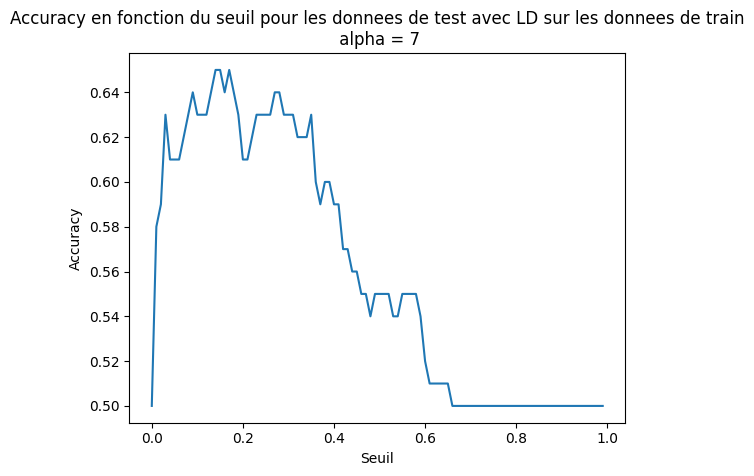

In [24]:
acc_list = []
f1_list = []
prec_list = []
recall_list = []

y_true = test_source_y.numpy()

for i in range(100):
    seuil = i/100
    y_pred = (np.array(lens_depth_ext_fermat) < seuil).astype(int)
    acc_list.append(metrics.accuracy_score(y_true, y_pred))
    f1_list.append(metrics.f1_score(y_true, y_pred, pos_label=1))
    prec_list.append(metrics.precision_score(y_true, y_pred, pos_label=1, zero_division=0))
    recall_list.append(metrics.recall_score(y_true, y_pred, pos_label=1, zero_division=0))
    

plt.plot(np.arange(100)/100, acc_list)
plt.xlabel("Seuil")
plt.ylabel("Accuracy")
plt.title(f"Accuracy en fonction du seuil pour les donnees de test avec LD sur les donnees de train\n alpha = {alpha2}")
plt.show()

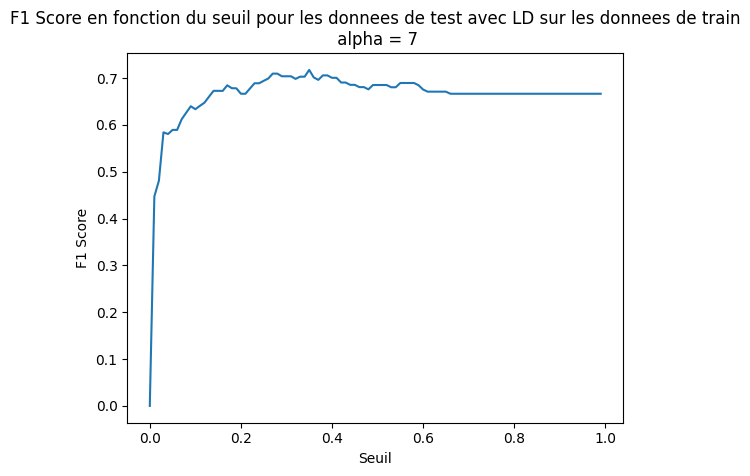

In [25]:
plt.plot(np.arange(100)/100, f1_list)
plt.xlabel("Seuil")
plt.ylabel("F1 Score")
plt.title(f"F1 Score en fonction du seuil pour les donnees de test avec LD sur les donnees de train\n alpha = {alpha2}")
plt.show()

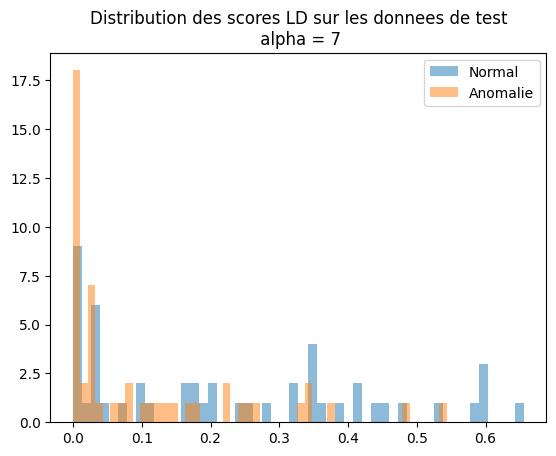

In [26]:
plt.hist(np.array(lens_depth_ext_fermat)[test_source_y == 0], bins=50, alpha=0.5, label='Normal')
plt.hist(np.array(lens_depth_ext_fermat)[test_source_y == 1], bins=50, alpha=0.5, label='Anomalie')
plt.legend()
plt.title(f"Distribution des scores LD sur les donnees de test\n alpha = {alpha2}")
plt.show()

## Resultats:

In [27]:
print("Methode            |  Accuracy maximale    |  Seuil optimal")
print("----------------------------------------------------------------")
print(f"LD dim=768         |  {max(acc_list):.4f}               |  {(np.argmax(acc_list)/100):.2f}")

Methode            |  Accuracy maximale    |  Seuil optimal
----------------------------------------------------------------
LD dim=768         |  0.6500               |  0.14


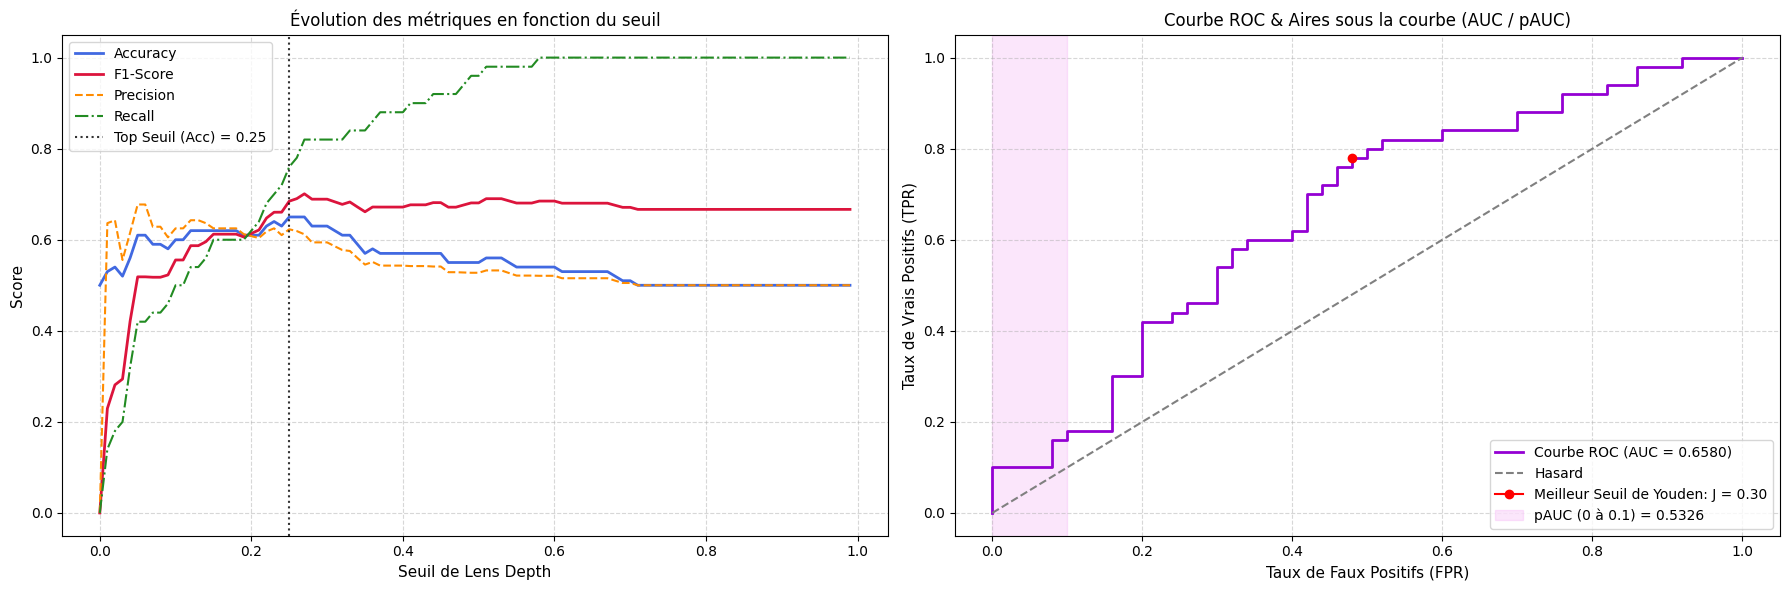

In [ ]:
y_true = test_source_y.int().numpy()
ld_scores = np.array(lens_depth_ext_fermat)

seuils = np.arange(100) / 100
acc_list = []
f1_list = []
precision_list = []
recall_list = []

for seuil in seuils:
    y_pred = (ld_scores < seuil).astype(int)
    acc_list.append(metrics.accuracy_score(y_true, y_pred))
    f1_list.append(metrics.f1_score(y_true, y_pred, pos_label=1))
    precision_list.append(metrics.precision_score(y_true, y_pred, pos_label=1, zero_division=0))
    recall_list.append(metrics.recall_score(y_true, y_pred, pos_label=1, zero_division=0))
    

fpr, tpr, _ = metrics.roc_curve(y_true, -ld_scores)
auc_score = metrics.auc(fpr, tpr)

max_fpr = 0.1
pauc_score = metrics.roc_auc_score(y_true, -ld_scores, max_fpr=max_fpr)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6))

ax1.plot(seuils, acc_list, label="Accuracy", color="royalblue", lw=2)
ax1.plot(seuils, f1_list, label="F1-Score", color="crimson", lw=2)
ax1.plot(seuils, precision_list, label="Precision", color="darkorange", linestyle="--")
ax1.plot(seuils, recall_list, label="Recall", color="forestgreen", linestyle="-.")

meilleur_seuil = seuils[np.argmax(acc_list)]
ax1.axvline(x=meilleur_seuil, color="black", linestyle=":", alpha=0.8, 
            label=f"Top Seuil (Acc) = {meilleur_seuil}")

ax1.set_xlabel("Seuil de Lens Depth", fontsize=11)
ax1.set_ylabel("Score", fontsize=11)
ax1.set_title("Évolution des métriques en fonction du seuil", fontsize=12)
ax1.legend()
ax1.grid(True, linestyle='--', alpha=0.5)

ax2.plot(fpr, tpr, color="darkviolet", lw=2, label=f"Courbe ROC (AUC = {auc_score:.4f})")

ax2.plot([0, 1], [0, 1], color="gray", linestyle="--", label="Hasard")

J = tpr - fpr
ix = np.argmax(J)
ax2.plot(fpr[ix], tpr[ix], marker='o', color='red',  label=f"Meilleur Seuil de Youden: J = {seuils[ix]:.2f}")

ax2.axvspan(0, max_fpr, color='violet', alpha=0.2, 
            label=f"pAUC (0 à {max_fpr}) = {pauc_score:.4f}")

ax2.set_xlabel("Taux de Faux Positifs (FPR)", fontsize=11)
ax2.set_ylabel("Taux de Vrais Positifs (TPR)", fontsize=11)
ax2.set_title("Courbe ROC & Aires sous la courbe (AUC / pAUC)", fontsize=12)
ax2.legend(loc="lower right")
ax2.grid(True, linestyle='--', alpha=0.5)




plt.tight_layout()
plt.show()

In [31]:
# alphas
alpha1 = 20
auc_list = []
for alpha2 in range(1, alpha1+1):
    points = copy.deepcopy(train_source_X)
    dist_mat = distance_matrix(points, points)
    fermat_dist_mat = fermat_function(dist_mat, alpha=alpha2)
    points_test = copy.deepcopy(test_source_X)
    lens_depth_ext_fermat = []
    for i in range(points_test.shape[0]):
        dist_array = distance_matrix(points,points_test[i].reshape((1,-1)))
        dist_ext = fermat_function_ext(fermat_dist_mat, dist_array,alpha=alpha2)
        lens_depth_ext_fermat += [lens_depth_ext_function(fermat_dist_mat, dist_ext)]

    print(min(lens_depth_ext_fermat), max(lens_depth_ext_fermat))
    acc_list = []
    f1_list = []
    prec_list = []
    recall_list = []

    y_true = test_source_y.numpy()

    for i in range(100):
        seuil = i/100
        y_pred = (np.array(lens_depth_ext_fermat) < seuil).astype(int)
        acc_list.append(metrics.accuracy_score(y_true, y_pred))
        f1_list.append(metrics.f1_score(y_true, y_pred, pos_label=1))
        prec_list.append(metrics.precision_score(y_true, y_pred, pos_label=1, zero_division=0))
        recall_list.append(metrics.recall_score(y_true, y_pred, pos_label=1, zero_division=0))
        
        
    y_true = test_source_y.int().numpy()
    ld_scores = np.array(lens_depth_ext_fermat)

    seuils = np.arange(100) / 100
    acc_list = []
    f1_list = []
    precision_list = []
    recall_list = []


    # for seuil in seuils:
    #     y_pred = (ld_scores < seuil).astype(int)
    #     acc_list.append(metrics.accuracy_score(y_true, y_pred))
    #     f1_list.append(metrics.f1_score(y_true, y_pred, pos_label=1))
    #     precision_list.append(metrics.precision_score(y_true, y_pred, pos_label=1, zero_division=0))
    #     recall_list.append(metrics.recall_score(y_true, y_pred, pos_label=1, zero_division=0))
        

    fpr, tpr, _ = metrics.roc_curve(y_true, -ld_scores)
    auc_score = metrics.auc(fpr, tpr)
    auc_list.append(auc_score)

2.042671405664328e-06 0.6866194809571958
0.0 0.7017904014870647
0.0 0.7199763050116943
0.0 0.7024501843510944


KeyboardInterrupt: 

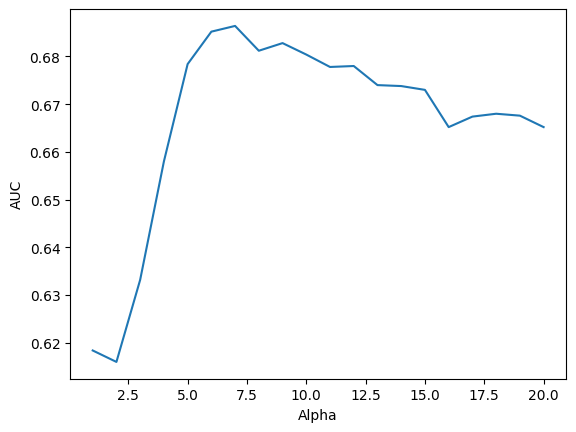

In [ ]:
plt.plot(range(1, alpha1+1), auc_list)
plt.xlabel("Alpha")
plt.ylabel("AUC")
plt.show()

In [ ]:
print(np.argmax(auc_list)+1, max(auc_list))

7 0.6864
